# Skin Disease Classification — HAM10000

## Deep Learning Model

It keeps the original project flow:
1. Load HAM10000 metadata and images
2. Clean and explore the data
3. Prepare image tensors and labels
4. Train the original-style CNN
5. Evaluate with accuracy, confusion matrix and classification report
6. Train a transfer-learning MobileNet model
7. Save the trained model
8. Run a single-image prediction
9. Generate a LIME-style image explanation



In [ ]:
!pip -q install lime


In [ ]:
import os
import zipfile
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# from google.colab import files

# uploaded = files.upload()

# zip_files = [name for name in uploaded if name.lower().endswith(".zip")]

# if zip_files:
#     zip_path = zip_files[0]
#     extract_dir = "/content/ham10000"
#     os.makedirs(extract_dir, exist_ok=True)

#     with zipfile.ZipFile(zip_path, "r") as z:
#         z.extractall(extract_dir)

#     DATASET_DIR = extract_dir
#     print("Extracted to:", DATASET_DIR)
# else:
#     print("No ZIP uploaded. If you are using Drive, set DATASET_DIR manually in the next cell.")


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

DATASET_DIR = "/content/drive/MyDrive/HAM10000"

# If your ZIP extraction created another nested folder, the recursive search below
# will still find HAM10000_metadata.csv and the JPG files.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print("Current directory:", os.getcwd())
print("Files in current directory:")
print(os.listdir("/content"))

Current directory: /content
Files in current directory:
['.config', 'drive', 'HAM10000', 'sample_data']


In [ ]:
import os

zip_path = None

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'HAM10000.zip' in files:
        zip_path = os.path.join(root, 'HAM10000.zip')
        break

print("ZIP file found:", zip_path)

ZIP file found: /content/drive/MyDrive/HAM10000.zip


In [ ]:
import zipfile
import os

if zip_path is None:
    raise FileNotFoundError("HAM10000.zip was not found in Google Drive.")

extract_dir = '/content/HAM10000'

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_dir)

print("Dataset extracted to:", extract_dir)

Dataset extracted to: /content/HAM10000


In [ ]:
import glob
import zipfile
import os

# Find any nested zip files inside the extracted directory
nested_zips = glob.glob(os.path.join(extract_dir, "**", "*.zip"), recursive=True)
print("Found nested ZIP files to extract:", nested_zips)

for n_zip in nested_zips:
    print(f"Extracting nested zip: {n_zip}...")
    with zipfile.ZipFile(n_zip, 'r') as z:
        # Extract images directly into the main HAM10000 folder
        z.extractall(extract_dir)

# Let's verify how many JPG images we now have extracted
all_jpgs = glob.glob(os.path.join(extract_dir, "**", "*.jpg"), recursive=True)
print(f"Total JPG images found after extracting nested ZIPs: {len(all_jpgs)}")

Found nested ZIP files to extract: []
Total JPG images found after extracting nested ZIPs: 20030


In [ ]:
metadata_path = None

for root, dirs, files in os.walk(extract_dir):
    if 'HAM10000_metadata.csv' in files:
        metadata_path = os.path.join(
            root, 'HAM10000_metadata.csv'
        )
        break

if metadata_path is None:
    raise FileNotFoundError(
        "Metadata CSV not found. Check the ZIP contents."
    )

DATASET_DIR = os.path.dirname(metadata_path)

print("Metadata:", metadata_path)
print("Dataset directory:", DATASET_DIR)

Metadata: /content/HAM10000/HAM10000_metadata.csv
Dataset directory: /content/HAM10000


In [ ]:
import pandas as pd

df = pd.read_csv(metadata_path)

print(df.head())
print("Number of records:", len(df))

     lesion_id      image_id   dx dx_type   age   sex localization
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear
Number of records: 10015


## 3. Load and clean the metadata


In [ ]:
df = pd.read_csv(metadata_path)

print("Shape:", df.shape)
display(df.head())
display(df.dtypes)
display(df.describe(include="all"))

Shape: (10015, 7)


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


,0
lesion_id,object
image_id,object
dx,object
dx_type,object
age,float64
sex,object
localization,object


,lesion_id,image_id,dx,dx_type,age,sex,localization
count,10015,10015,10015,10015,9958.000000,10015,10015
unique,7470,10015,7,4,NaN,3,15
top,HAM_0003789,ISIC_0032258,nv,histo,NaN,male,back
freq,6,1,6705,5340,NaN,5406,2192
mean,NaN,NaN,NaN,NaN,51.863828,NaN,NaN
std,NaN,NaN,NaN,NaN,16.968614,NaN,NaN
min,NaN,NaN,NaN,NaN,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,40.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,50.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,65.000000,NaN,NaN


In [ ]:
import pandas as pd
import glob
import os

# 1. Reset and load fresh metadata (10,015 rows)
df = pd.read_csv(metadata_path)
print("1. Metadata loaded successfully. Rows:", len(df))

# 2. Clean data
df["age"] = df["age"].fillna(df["age"].mean())
df = df[df["age"] != 0].copy()
df = df[df["sex"] != "unknown"].copy()
print("2. Metadata cleaned. Rows remaining:", len(df))

# 3. Map to extracted image files (using extract_dir /content/HAM10000)
lesion_type_dict = {
    "nv": "Melanocytic nevi",
    "mel": "Melanoma",
    "bkl": "Benign keratosis-like lesions",
    "bcc": "Basal cell carcinoma",
    "akiec": "Actinic keratoses",
    "vasc": "Vascular lesions",
    "df": "Dermatofibroma"
}

# Find extracted JPG images dynamically
image_files = glob.glob(os.path.join(extract_dir, "**", "*.jpg"), recursive=True)
print(f"3. Found {len(image_files)} image files in {extract_dir}")

# Map image_id -> path
imageid_path_dict = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_files
}

df["path"] = df["image_id"].map(imageid_path_dict)
df["cell_type"] = df["dx"].map(lesion_type_dict)

# Drop rows where images cannot be matched
df = df.dropna(subset=["path", "cell_type"]).copy()

# Setup label indices
class_names = [
    "Actinic keratoses",
    "Basal cell carcinoma",
    "Benign keratosis-like lesions",
    "Dermatofibroma",
    "Melanoma",
    "Melanocytic nevi",
    "Vascular lesions"
]
class_to_idx = {name: i for i, name in enumerate(class_names)}
df["cell_type_idx"] = df["cell_type"].map(class_to_idx)

print("\n--- SUCCESS ---")
print("Total mapped and usable dataset rows:", len(df))
display(df.head())

1. Metadata loaded successfully. Rows: 10015
2. Metadata cleaned. Rows remaining: 9921
3. Found 20030 image files in /content/HAM10000

--- SUCCESS ---
Total mapped and usable dataset rows: 9921


,lesion_id,image_id,dx,dx_type,age,sex,localization,path,cell_type,cell_type_idx
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/content/HAM10000/HAM10000_images_part_1/ISIC_...,Benign keratosis-like lesions,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/content/HAM10000/HAM10000_images_part_1/ISIC_...,Benign keratosis-like lesions,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/content/HAM10000/HAM10000_images_part_1/ISIC_...,Benign keratosis-like lesions,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/content/HAM10000/HAM10000_images_part_1/ISIC_...,Benign keratosis-like lesions,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/content/HAM10000/ham10000_images_part_2/ISIC_...,Benign keratosis-like lesions,2


In [ ]:
print("Missing values before cleaning:")
display(df.isnull().sum())

df["age"] = df["age"].fillna(df["age"].mean())

# Keep the same practical filtering used by the original notebook.
df = df[df["age"] != 0].copy()
df = df[df["sex"] != "unknown"].copy()

print("Shape after cleaning:", df.shape)
display(df.isnull().sum())


Missing values before cleaning:


,0
lesion_id,0
image_id,0
dx,0
dx_type,0
age,0
sex,0
localization,0
path,0
cell_type,0
cell_type_idx,0


Shape after cleaning: (9921, 10)


,0
lesion_id,0
image_id,0
dx,0
dx_type,0
age,0
sex,0
localization,0
path,0
cell_type,0
cell_type_idx,0


In [ ]:
lesion_type_dict = {
    "nv": "Melanocytic nevi",
    "mel": "Melanoma",
    "bkl": "Benign keratosis-like lesions",
    "bcc": "Basal cell carcinoma",
    "akiec": "Actinic keratoses",
    "vasc": "Vascular lesions",
    "df": "Dermatofibroma"
}

# Find all JPG images in the extracted dataset directory dynamically
import glob
image_files = glob.glob(os.path.join(DATASET_DIR, "**", "*.jpg"), recursive=True)

# Map image_id -> actual JPG path.
imageid_path_dict = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_files
}

df["path"] = df["image_id"].map(imageid_path_dict)
df["cell_type"] = df["dx"].map(lesion_type_dict)

# Drop rows for which an image could not be found.
df = df.dropna(subset=["path", "cell_type"]).copy()

# Fixed label mapping makes results reproducible.
class_names = [
    "Actinic keratoses",
    "Basal cell carcinoma",
    "Benign keratosis-like lesions",
    "Dermatofibroma",
    "Melanoma",
    "Melanocytic nevi",
    "Vascular lesions"
]

class_to_idx = {name: i for i, name in enumerate(class_names)}
df["cell_type_idx"] = df["cell_type"].map(class_to_idx)

print("Usable images:", len(df))
if len(df) > 0:
    display(df.head())
else:
    print("Warning: 0 images mapped. Make sure to run the extraction cell first to unpack the zip archives!")

Usable images: 9921


,lesion_id,image_id,dx,dx_type,age,sex,localization,path,cell_type,cell_type_idx
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/content/HAM10000/HAM10000_images_part_1/ISIC_...,Benign keratosis-like lesions,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/content/HAM10000/HAM10000_images_part_1/ISIC_...,Benign keratosis-like lesions,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/content/HAM10000/HAM10000_images_part_1/ISIC_...,Benign keratosis-like lesions,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/content/HAM10000/HAM10000_images_part_1/ISIC_...,Benign keratosis-like lesions,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/content/HAM10000/ham10000_images_part_2/ISIC_...,Benign keratosis-like lesions,2


## 4. Explore the dataset


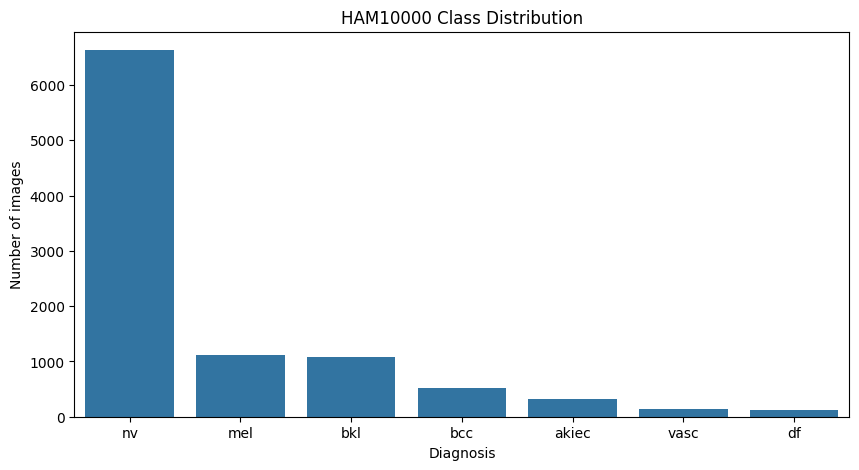

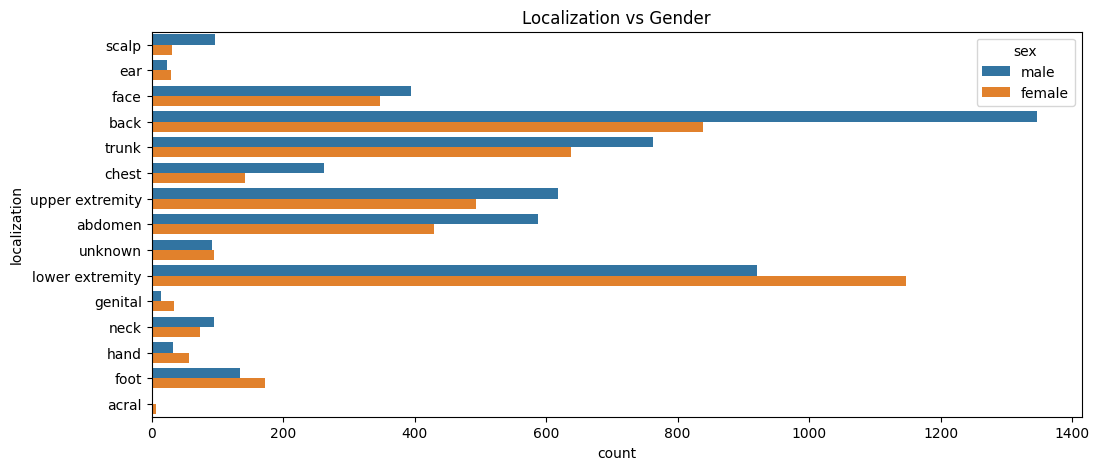

In [ ]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="dx", order=df["dx"].value_counts().index)
plt.title("HAM10000 Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of images")
plt.show()

plt.figure(figsize=(12, 5))
sns.countplot(data=df, y="localization", hue="sex")
plt.title("Localization vs Gender")
plt.show()


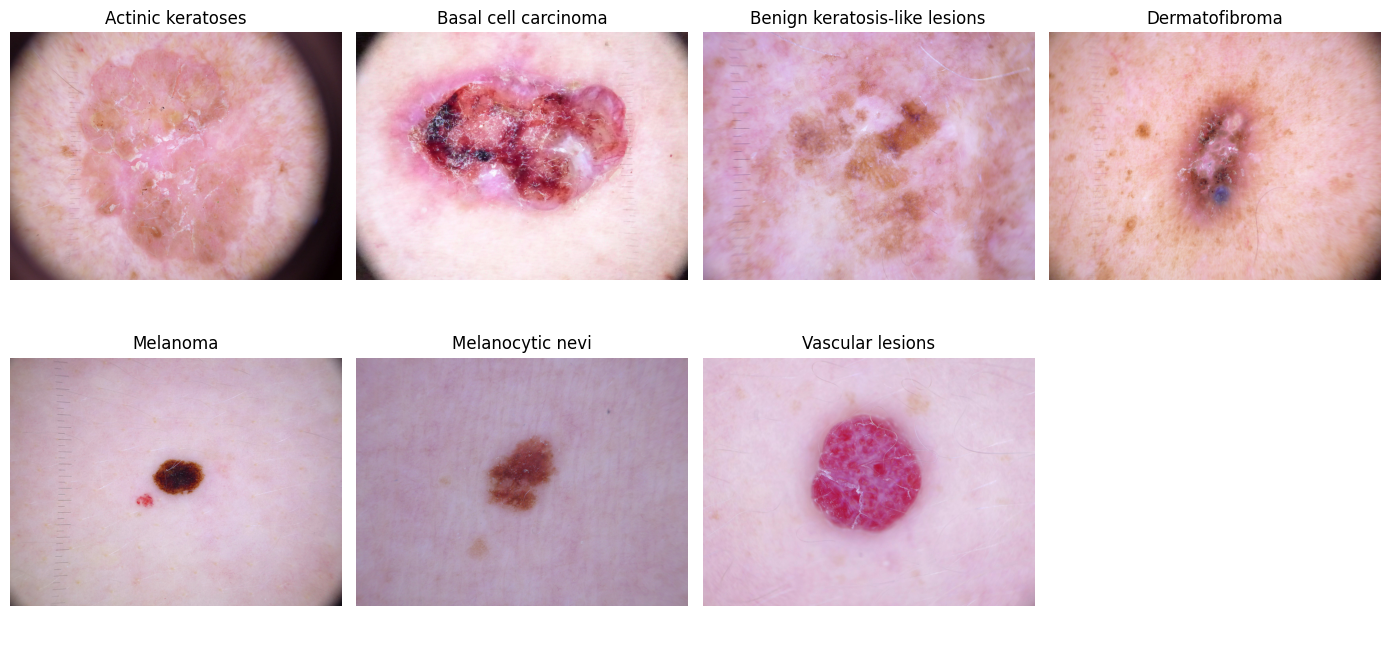

In [ ]:
# Display one example image from each class.
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.ravel()

# Ensure we have data before plotting
if len(df) > 0:
    for i, class_name in enumerate(class_names):
        class_df = df[df["cell_type"] == class_name]
        if len(class_df) > 0:
            row = class_df.iloc[0]
            img = Image.open(row["path"]).convert("RGB")
            axes[i].imshow(img)
            axes[i].set_title(class_name)
        axes[i].axis("off")
else:
    print("Error: DataFrame is empty. Please run cell 'a6b2637f' to reload the dataset first!")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

## 5. Load images

The images are loaded only once into NumPy arrays.


In [ ]:
IMG_HEIGHT = 100
IMG_WIDTH = 125
NUM_CLASSES = 7

def load_image(path):
    img = Image.open(path).convert("RGB")
    img = img.resize((IMG_WIDTH, IMG_HEIGHT))
    return np.asarray(img, dtype=np.float32)

X = np.stack([load_image(path) for path in df["path"]])
y = df["cell_type_idx"].to_numpy()

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (9921, 100, 125, 3)
y shape: (9921,)


In [ ]:
# Train/test split with stratification so each class is represented.
X_train, X_test, y_train_idx, y_test_idx = train_test_split(
    X, y,
    test_size=0.25,
    random_state=666,
    stratify=y
)

X_train, X_val, y_train_idx, y_val_idx = train_test_split(
    X_train, y_train_idx,
    test_size=0.10,
    random_state=999,
    stratify=y_train_idx
)

# Normalize using the training set only.
train_mean = X_train.mean()
train_std = X_train.std()

X_train = (X_train - train_mean) / train_std
X_val = (X_val - train_mean) / train_std
X_test = (X_test - train_mean) / train_std

y_train = to_categorical(y_train_idx, NUM_CLASSES)
y_val = to_categorical(y_val_idx, NUM_CLASSES)
y_test = to_categorical(y_test_idx, NUM_CLASSES)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


Train: (6696, 100, 125, 3) (6696, 7)
Validation: (744, 100, 125, 3) (744, 7)
Test: (2481, 100, 125, 3) (2481, 7)


## 6. Original-style CNN

This replaces the deprecated Keras APIs from the original notebook with current `tf.keras` APIs.

Architecture:
`Conv2D → Conv2D → MaxPool → Dropout` repeated three times, followed by dense layers and a 7-class softmax output.


In [ ]:
cnn = Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.16),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.20),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 100, 125, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 125, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 50, 62, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 50, 62, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 25, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 25, 31, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 25, 31, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 12, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 11520)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,949,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,067,239 (11.70 MB)

 Trainable params: 3,067,239 (11.70 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    horizontal_flip=True,
    vertical_flip=True
)

datagen.fit(X_train)

callbacks = [
    ReduceLROnPlateau(
        monitor="val_accuracy",
        patience=4,
        factor=0.5,
        min_lr=1e-6,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

history_cnn = cnn.fit(
    datagen.flow(X_train, y_train, batch_size=16),
    epochs=30,
    validation_data=(X_val, y_val),
    callbacks=callbacks,
    verbose=1
)


Epoch 1/30
419/419 ━━━━━━━━━━━━━━━━━━━━ 58s 105ms/step - accuracy: 0.6616 - loss: 1.0501 - val_accuracy: 0.6680 - val_loss: 1.0140 - learning_rate: 1.0000e-04
Epoch 2/30
419/419 ━━━━━━━━━━━━━━━━━━━━ 28s 66ms/step - accuracy: 0.6650 - loss: 0.9291 - val_accuracy: 0.6707 - val_loss: 0.8954 - learning_rate: 1.0000e-04
Epoch 3/30
419/419 ━━━━━━━━━━━━━━━━━━━━ 26s 62ms/step - accuracy: 0.6728 - loss: 0.8884 - val_accuracy: 0.6922 - val_loss: 0.8758 - learning_rate: 1.0000e-04
Epoch 4/30
419/419 ━━━━━━━━━━━━━━━━━━━━ 26s 62ms/step - accuracy: 0.6782 - loss: 0.8542 - val_accuracy: 0.7164 - val_loss: 0.8583 - learning_rate: 1.0000e-04
Epoch 5/30
419/419 ━━━━━━━━━━━━━━━━━━━━ 26s 61ms/step - accuracy: 0.7007 - loss: 0.8262 - val_accuracy: 0.7137 - val_loss: 0.8364 - learning_rate: 1.0000e-04
Epoch 6/30
419/419 ━━━━━━━━━━━━━━━━━━━━ 27s 65ms/step - accuracy: 0.7085 - loss: 0.7965 - val_accuracy: 0.6801 - val_loss: 0.8829 - learning_rate: 1.0000e-04
Epoch 7/30
419/419 ━━━━━━━━━━━━━━━━━━━━ 27s 65ms/st

CNN test accuracy: 76.42%


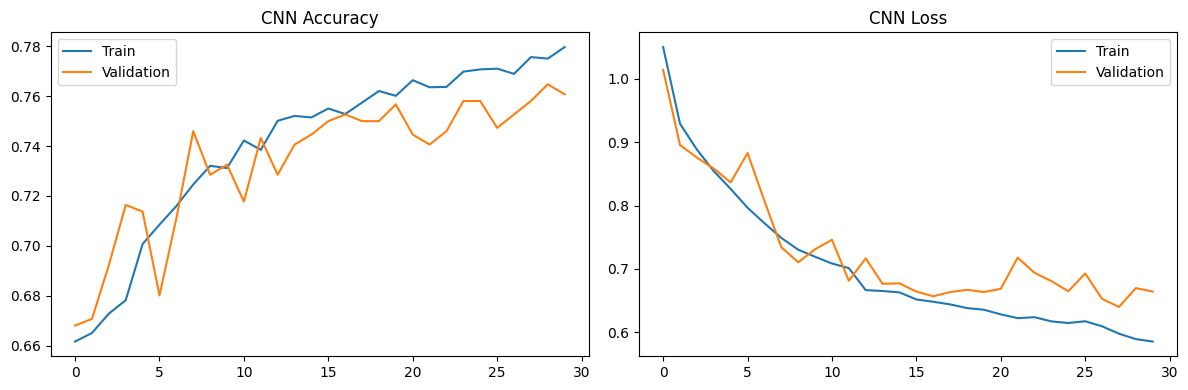

In [ ]:
test_loss, test_acc = cnn.evaluate(X_test, y_test, verbose=0)
print(f"CNN test accuracy: {test_acc * 100:.2f}%")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Train")
plt.plot(history_cnn.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Train")
plt.plot(history_cnn.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.legend()

plt.tight_layout()
plt.show()


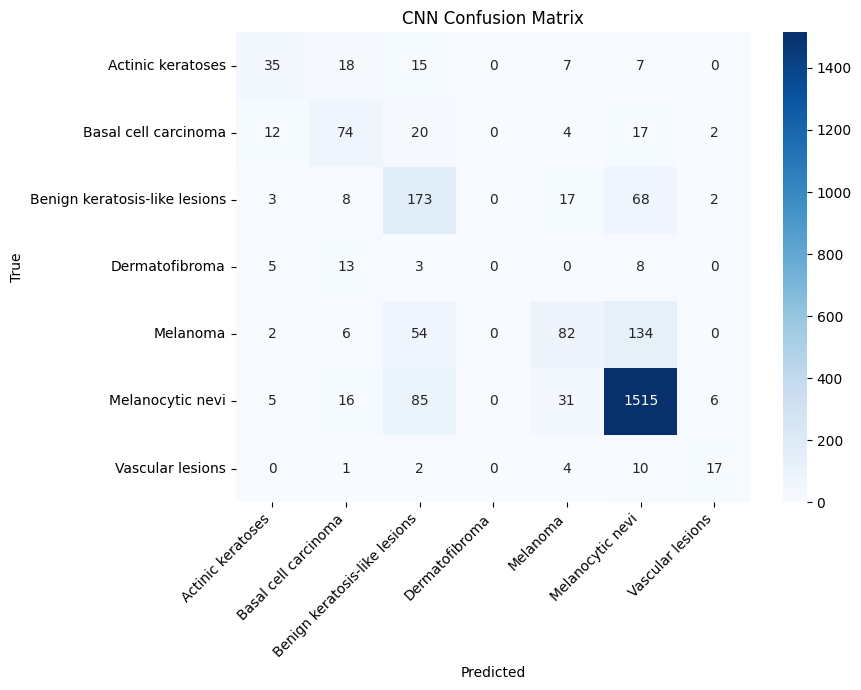

                               precision    recall  f1-score   support

            Actinic keratoses     0.5645    0.4268    0.4861        82
         Basal cell carcinoma     0.5441    0.5736    0.5585       129
Benign keratosis-like lesions     0.4915    0.6384    0.5554       271
               Dermatofibroma     0.0000    0.0000    0.0000        29
                     Melanoma     0.5655    0.2950    0.3877       278
             Melanocytic nevi     0.8613    0.9138    0.8867      1658
             Vascular lesions     0.6296    0.5000    0.5574        34

                     accuracy                         0.7642      2481
                    macro avg     0.5224    0.4782    0.4903      2481
                 weighted avg     0.7482    0.7642    0.7494      2481



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# CNN confusion matrix + classification report
cnn_probs = cnn.predict(X_test, verbose=0)
cnn_pred = np.argmax(cnn_probs, axis=1)

cm = confusion_matrix(y_test_idx, cnn_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("CNN Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(classification_report(
    y_test_idx,
    cnn_pred,
    target_names=class_names,
    digits=4
))


## 7. Transfer learning with MobileNet

Modern TensorFlow makes this considerably simpler and more reliable than changing the input layers of an old pretrained model.

MobileNet expects **224 × 224** images, so this section uses a TensorFlow data pipeline that resizes the already loaded images.


In [ ]:
MOBILE_SIZE = 224

# Convert the original uint8-like image values back to [0, 1] for MobileNet.
# X was normalized above, so reconstruct images from the original dataframe paths.
def load_mobile_batch(paths):
    imgs = []
    for path in paths:
        img = Image.open(path).convert("RGB").resize((MOBILE_SIZE, MOBILE_SIZE))
        imgs.append(np.asarray(img, dtype=np.float32) / 255.0)
    return np.stack(imgs)

# For a Colab T4, loading the full 224x224 dataset is usually manageable.
X_mobile = np.stack([load_mobile_batch([p])[0] for p in df["path"]])

Xm_train, Xm_test, ym_train_idx, ym_test_idx = train_test_split(
    X_mobile, y,
    test_size=0.25,
    random_state=666,
    stratify=y
)

Xm_train, Xm_val, ym_train_idx, ym_val_idx = train_test_split(
    Xm_train, ym_train_idx,
    test_size=0.10,
    random_state=999,
    stratify=ym_train_idx
)

ym_train = to_categorical(ym_train_idx, NUM_CLASSES)
ym_val = to_categorical(ym_val_idx, NUM_CLASSES)
ym_test = to_categorical(ym_test_idx, NUM_CLASSES)

print(Xm_train.shape, Xm_val.shape, Xm_test.shape)


NameError: name 'np' is not defined

In [ ]:
base_model = keras.applications.MobileNet(
    input_shape=(MOBILE_SIZE, MOBILE_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

mobile_model = Sequential([
    layers.Input(shape=(MOBILE_SIZE, MOBILE_SIZE, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.25),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

mobile_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.TopKCategoricalAccuracy(k=2, name="top_2_accuracy"),
        keras.metrics.TopKCategoricalAccuracy(k=3, name="top_3_accuracy")
    ]
)

mobile_model.summary()


In [ ]:
# Give melanoma extra weight, following the intent of the original notebook.
# The class indices here correspond to class_names above.
class_weights = {
    0: 1.0,  # Actinic keratoses
    1: 1.0,  # Basal cell carcinoma
    2: 1.0,  # Benign keratosis-like lesions
    3: 1.0,  # Dermatofibroma
    4: 3.0,  # Melanoma
    5: 1.0,  # Melanocytic nevi
    6: 1.0   # Vascular lesions
}

mobile_callbacks = [
    ModelCheckpoint(
        "/content/best_mobilenet.keras",
        monitor="val_top_3_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_top_3_accuracy",
        factor=0.5,
        patience=2,
        mode="max",
        min_lr=1e-6,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_top_3_accuracy",
        patience=5,
        mode="max",
        restore_best_weights=True,
        verbose=1
    )
]

history_mobile = mobile_model.fit(
    Xm_train, ym_train,
    validation_data=(Xm_val, ym_val),
    epochs=10,
    batch_size=32,
    class_weight=class_weights,
    callbacks=mobile_callbacks,
    verbose=1
)


In [ ]:
mobile_results = mobile_model.evaluate(Xm_test, ym_test, verbose=0)
for name, value in zip(mobile_model.metrics_names, mobile_results):
    print(f"{name}: {value:.4f}")


In [ ]:
# MobileNet classification report
mobile_probs = mobile_model.predict(Xm_test, verbose=0)
mobile_pred = np.argmax(mobile_probs, axis=1)

print(classification_report(
    ym_test_idx,
    mobile_pred,
    target_names=class_names,
    digits=4
))

cm_mobile = confusion_matrix(ym_test_idx, mobile_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_mobile,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("MobileNet Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 8. Save the models



In [ ]:
cnn.save("/content/ham10000_cnn.keras")
mobile_model.save("/content/ham10000_mobilenet.keras")

print("Saved:")
print("/content/ham10000_cnn.keras")
print("/content/ham10000_mobilenet.keras")


In [ ]:
# Optional: download the MobileNet model
from google.colab import files
files.download("/content/ham10000_mobilenet.keras")


## 9. Predict a new skin-lesion image

Upload a dermoscopic image and the model will return the probabilities for the seven HAM10000 classes.

In [ ]:
from google.colab import files

uploaded = files.upload()
new_image_path = next(iter(uploaded))

img = Image.open(new_image_path).convert("RGB")
img_display = img.copy()

img_cnn = img.resize((IMG_WIDTH, IMG_HEIGHT))
img_cnn = np.asarray(img_cnn, dtype=np.float32)

img_cnn = (img_cnn - train_mean) / train_std
img_cnn = np.expand_dims(img_cnn, axis=0)

probs = cnn.predict(img_cnn, verbose=0)[0]
order = np.argsort(probs)[::-1]

plt.figure(figsize=(5, 5))
plt.imshow(img_display)
plt.axis("off")
plt.title("Uploaded image")
plt.show()

print("Top predictions:")
for idx in order[:5]:
    print(f"{class_names[idx]:40s} {probs[idx]*100:.2f}%")


## 10. LIME explanation

# LIME section:
Highlight image regions that influence a prediction.

LIME can be slow because it evaluates many perturbed versions of the image.


In [ ]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

explainer = lime_image.LimeImageExplainer()

# Use the original RGB image in [0, 1] because LIME will create perturbed images.
lime_img = np.asarray(img_display.resize((IMG_WIDTH, IMG_HEIGHT)), dtype=np.float32) / 255.0

def predict_for_lime(batch):
    batch = np.asarray(batch, dtype=np.float32)
    # Convert [0,1] images to the normalization used by the CNN.
    batch = batch * 255.0
    batch = (batch - train_mean) / train_std
    return cnn.predict(batch, verbose=0)

explanation = explainer.explain_instance(
    lime_img,
    predict_for_lime,
    top_labels=3,
    hide_color=0,
    num_samples=500
)

top_label = explanation.top_labels[0]

temp, mask = explanation.get_image_and_mask(
    top_label,
    positive_only=False,
    num_features=10,
    hide_rest=False
)

plt.figure(figsize=(8, 8))
plt.imshow(mark_boundaries(temp, mask))
plt.title(f"LIME explanation: {class_names[top_label]}")
plt.axis("off")
plt.show()
